In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("device:", device)

device: cpu


In [2]:
N_SUBJ = 64
N_REL = 4
N_OBJ = 64

BOS = 0
SUBJ_OFFSET = 1
REL_OFFSET = 1 + N_SUBJ
QUERY = 1 + N_SUBJ + N_REL
VOCAB_SIZE = QUERY + 1
SEQ_LEN = 4

#VOCAB_SIZE = (
 #   1 + N_SUBJ + N_REL
#)

# Ogni relazione associa i 64 soggetti
# a una permutazione dei 64 oggetti.
mapping = torch.stack(
    [
        torch.randperm(N_OBJ)
        for _ in range(N_REL)
    ],
    dim=1
)

def make_prompt(s, r):

    return torch.tensor(
        [
            BOS,
            SUBJ_OFFSET + s,
            REL_OFFSET + r,
            QUERY
        ],
        dtype=torch.long
    )

X_list = []
y_list = []
meta = []

for s in range(N_SUBJ):

    for r in range(N_REL):

        X_list.append(
            make_prompt(s, r)
        )

        y_list.append(
            mapping[s, r]
        )

        meta.append(
            (s, r)
        )

X = torch.stack(X_list)
y = torch.tensor(y_list)

print(X.shape, y.shape)

torch.Size([256, 4]) torch.Size([256])


In [3]:
class CausalBlock(nn.Module):

    def __init__(
        self,
        d_model=64,
        n_heads=4,
        d_mlp=128
    ):
        super().__init__()

        self.ln1 = nn.LayerNorm(
            d_model
        )

        self.attn = nn.MultiheadAttention(
            d_model,
            n_heads,
            batch_first=True,
            dropout=0.0
        )

        self.ln2 = nn.LayerNorm(
            d_model
        )

        self.mlp = nn.Sequential(
            nn.Linear(
                d_model,
                d_mlp
            ),
            nn.GELU(),
            nn.Linear(
                d_mlp,
                d_model
            )
        )

    def forward(self, x):

        T = x.shape[1]

        mask = torch.triu(
            torch.ones(
                T,
                T,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        z = self.ln1(x)

        a, _ = self.attn(
            z,
            z,
            z,
            attn_mask=mask,
            need_weights=False
        )

        x = x + a

        x = (
            x
            +
            self.mlp(
                self.ln2(x)
            )
        )

        return x

In [4]:
class TinyFactTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        n_objects,
        n_layers=6,
        d_model=64,
        n_heads=4,
        d_mlp=128,
        max_len=8
    ):
        super().__init__()

        self.n_layers = n_layers

        self.token_embedding = (
            nn.Embedding(
                vocab_size,
                d_model
            )
        )

        self.position_embedding = (
            nn.Parameter(
                torch.randn(
                    1,
                    max_len,
                    d_model
                ) * 0.02
            )
        )

        self.blocks = nn.ModuleList([
            CausalBlock(
                d_model,
                n_heads,
                d_mlp
            )
            for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(
            d_model
        )

        self.readout = nn.Linear(
            d_model,
            n_objects,
            bias=False
        )

    def forward(
    self,
    tokens,
    patch=None,
    return_states=False
):

        T = tokens.shape[1]
    
        x = (
            self.token_embedding(tokens)
            +
            self.position_embedding[:, :T]
        )
    
        states = []
    
        for l, block in enumerate(
            self.blocks
        ):
    
            x = block(x)
    
            # --------------------------------
            # causal restoration / patching
            # --------------------------------
            if patch is not None:
    
                # Compatibilità:
                # se arriva un singolo dict,
                # trasformalo in lista.
                if isinstance(patch, dict):
                    patches = [patch]
                else:
                    patches = patch
    
                for p in patches:
    
                    if p["layer"] == l:
    
                        x = x.clone()
    
                        x[
                            :,
                            p["position"],
                            :
                        ] = p["value"]
    
            states.append(
                x.detach().clone()
            )
    
        logits = self.readout(
            self.ln_f(
                x[:, -1, :]
            )
        )
    
        if return_states:
            return logits, states
    
        return logits, None

In [5]:
model = TinyFactTransformer(
    VOCAB_SIZE,
    N_OBJ
).to(device)

In [6]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-3,
    weight_decay=1e-4
)

X_dev = X.to(device)
y_dev = y.to(device)

max_steps = 3000
batch_size = 128

for step in range(max_steps):

    model.train()

    ids = torch.randint(
        0,
        len(X_dev),
        (batch_size,),
        device=device
    )

    xb = X_dev[ids]
    yb = y_dev[ids]

    optimizer.zero_grad()

    logits, _ = model(xb)

    loss = F.cross_entropy(
        logits,
        yb
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        1.0
    )

    optimizer.step()

    if step % 100 == 0:

        model.eval()

        with torch.no_grad():

            logits_all, _ = model(
                X_dev
            )

            pred = logits_all.argmax(
                dim=1
            )

            acc = (
                pred == y_dev
            ).float().mean().item()

        print(
            f"step={step:4d} "
            f"| loss={loss.item():.5f} "
            f"| acc={acc:.4f}"
        )

        if acc > 0.995:
            print("Training complete.")
            break
        

step=   0 | loss=4.39905 | acc=0.0195
step= 100 | loss=0.05168 | acc=1.0000
Training complete.


In [7]:
torch.save(
    {
        "state_dict":
            model.state_dict(),

        "mapping":
            mapping,

        "config": {
            "N_SUBJ": N_SUBJ,
            "N_REL": N_REL,
            "N_OBJ": N_OBJ,
            "QUERY": QUERY,
            "VOCAB_SIZE":
                VOCAB_SIZE
        }
    },
    "phase4_tinyfact_checkpoint.pt"
)

In [8]:
s = 0
r = 0

s_bad = 1

clean = (
    make_prompt(
        s,
        r
    )
    .unsqueeze(0)
    .to(device)
)

corrupt = (
    make_prompt(
        s_bad,
        r
    )
    .unsqueeze(0)
    .to(device)
)

y_true = int(
    mapping[s, r]
)

y_bad = int(
    mapping[s_bad, r]
)

print(
    "true object:",
    y_true
)

print(
    "corrupt object's target:",
    y_bad
)

true object: 44
corrupt object's target: 46


In [9]:
def margin_score(
    logits,
    y_true,
    y_alt
):

    return (
        logits[0, y_true]
        -
        logits[0, y_alt]
    ).item()

In [10]:
def causal_trace_one(
    clean,
    corrupt,
    y_true,
    y_alt
):

    model.eval()

    with torch.no_grad():

        clean_logits, clean_states = (
            model(
                clean,
                return_states=True
            )
        )

        corrupt_logits, _ = model(
            corrupt
        )

        D_clean = margin_score(
            clean_logits,
            y_true,
            y_alt
        )

        D_corr = margin_score(
            corrupt_logits,
            y_true,
            y_alt
        )

        total_effect = (
            D_clean - D_corr
        )

        IE = np.zeros(
            (
                model.n_layers,
                clean.shape[1]
            )
        )

        for l in range(
            model.n_layers
        ):

            for pos in range(
                clean.shape[1]
            ):

                patch_value = (
                    clean_states[l][
                        :, pos, :
                    ]
                )

                patched_logits, _ = (
                    model(
                        corrupt,
                        patch={
                            "layer": l,
                            "position": pos,
                            "value":
                                patch_value
                        }
                    )
                )

                D_patch = margin_score(
                    patched_logits,
                    y_true,
                    y_alt
                )

                IE[l, pos] = (
                    D_patch - D_corr
                )

    return (
        IE,
        total_effect,
        D_clean,
        D_corr
    )

In [11]:
IE, TE, Dc, Dx = (
    causal_trace_one(
        clean,
        corrupt,
        y_true,
        y_bad
    )
)

print("Total effect:", TE)
print(IE)

Total effect: 18.12729263305664
[[ 0.         12.46176219  0.86168575  3.64347458]
 [ 0.         12.06815577  0.92805672  8.74770403]
 [ 0.          8.92222703  1.33390808 11.54698801]
 [ 0.          3.64145231  0.84332848 17.36834383]
 [ 0.          0.15570831  0.56798267 17.93484688]
 [ 0.          0.          0.         18.12729263]]


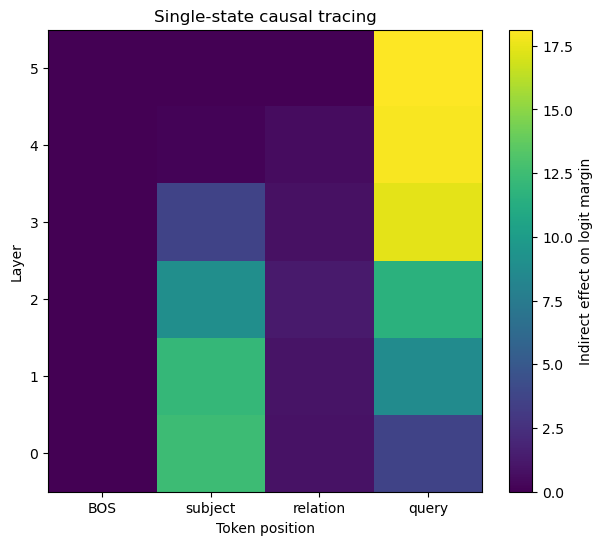

In [12]:
plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    IE,
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    label="Indirect effect on logit margin"
)

plt.xticks(
    [0,1,2,3],
    [
        "BOS",
        "subject",
        "relation",
        "query"
    ]
)

plt.xlabel(
    "Token position"
)

plt.ylabel(
    "Layer"
)

plt.title(
    "Single-state causal tracing"
)

plt.show()

In [13]:
all_IE = []

n_examples = 32

for k in range(n_examples):

    s = k % N_SUBJ
    r = k % N_REL

    s_bad = (
        s + 1
    ) % N_SUBJ

    clean = (
        make_prompt(s, r)
        .unsqueeze(0)
        .to(device)
    )

    corrupt = (
        make_prompt(
            s_bad,
            r
        )
        .unsqueeze(0)
        .to(device)
    )

    y_true = int(
        mapping[s, r]
    )

    y_alt = int(
        mapping[s_bad, r]
    )

    IE, TE, _, _ = (
        causal_trace_one(
            clean,
            corrupt,
            y_true,
            y_alt
        )
    )

    # frazione del total effect recuperata
    if abs(TE) > 1e-8:

        all_IE.append(
            IE / TE
        )

In [14]:
AIE = np.mean(
    np.stack(all_IE),
    axis=0
)

print(AIE)

[[0.         0.69613835 0.04114653 0.25247091]
 [0.         0.4549202  0.05663004 0.48084787]
 [0.         0.2810069  0.04599271 0.68741693]
 [0.         0.11943786 0.03820688 0.84916461]
 [0.         0.03877869 0.01669512 0.94788281]
 [0.         0.         0.         1.        ]]


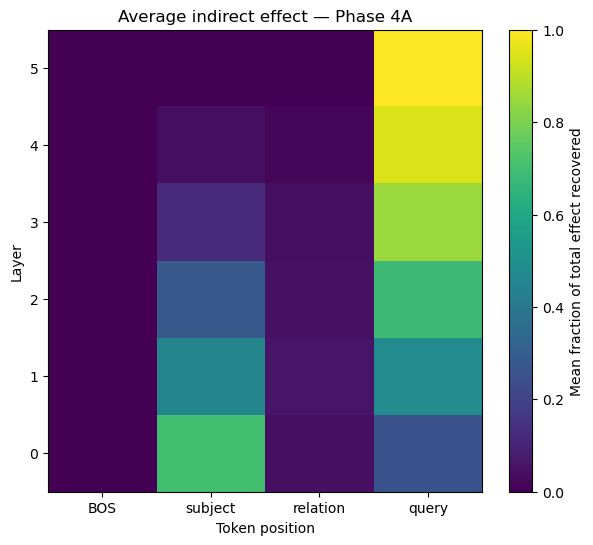

In [15]:
plt.figure(
    figsize=(7,6)
)

plt.imshow(
    AIE,
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    label="Mean fraction of total effect recovered"
)

plt.xticks(
    [0,1,2,3],
    [
        "BOS",
        "subject",
        "relation",
        "query"
    ]
)

plt.xlabel(
    "Token position"
)

plt.ylabel(
    "Layer"
)

plt.title(
    "Average indirect effect — Phase 4A"
)

plt.show()

QUERY = 1 + N_SUBJ + N_REL
VOCAB_SIZE = QUERY + 1
SEQ_LEN = 4

def make_prompt(s, r):

    return torch.tensor(
        [
            BOS,
            SUBJ_OFFSET + s,
            REL_OFFSET + r,
            QUERY
        ],
        dtype=torch.long
    )

In [16]:
import itertools

def second_order_trace_one(
    clean,
    corrupt,
    y_true,
    y_alt
):

    model.eval()

    with torch.no_grad():

        clean_logits, clean_states = model(
            clean,
            return_states=True
        )

        corrupt_logits, _ = model(
            corrupt
        )

        D0 = margin_score(
            corrupt_logits,
            y_true,
            y_alt
        )

        sites = [
            (l, pos)
            for l in range(model.n_layers)
            for pos in [1, 2, 3]
        ]

        single_D = {}

        # -------------------------
        # single restores
        # -------------------------

        for l, pos in sites:

            value = clean_states[l][
                :, pos, :
            ]

            logits, _ = model(
                corrupt,
                patch=[
                    {
                        "layer": l,
                        "position": pos,
                        "value": value
                    }
                ]
            )

            single_D[(l,pos)] = (
                margin_score(
                    logits,
                    y_true,
                    y_alt
                )
            )

        rows = []

        # -------------------------
        # double restores
        # -------------------------

        for i, j in itertools.combinations(
            sites,
            2
        ):

            l1, p1 = i
            l2, p2 = j

            logits, _ = model(
                corrupt,
                patch=[
                    {
                        "layer": l1,
                        "position": p1,
                        "value":
                            clean_states[l1][
                                :, p1, :
                            ]
                    },
                    {
                        "layer": l2,
                        "position": p2,
                        "value":
                            clean_states[l2][
                                :, p2, :
                            ]
                    }
                ]
            )

            Dij = margin_score(
                logits,
                y_true,
                y_alt
            )

            Di = single_D[i]
            Dj = single_D[j]

            Ji = Di - D0
            Jj = Dj - D0

            JD = (
                Dij
                - Di
                - Dj
                + D0
            )

            rows.append({
                "site_i": i,
                "site_j": j,

                "IE_i": Ji,
                "IE_j": Jj,

                "D_pair": Dij,

                "J_D": JD
            })

    return pd.DataFrame(rows)

In [17]:
pair_trace = second_order_trace_one(
    clean,
    corrupt,
    y_true,
    y_bad
)

print(
    pair_trace
    .sort_values(
        "J_D",
        ascending=False
    )
    .head(20)
)

     site_i  site_j      IE_i      IE_j    D_pair       J_D
1    (0, 1)  (0, 3)  2.158051 -0.337331  6.504333  2.997867
49   (1, 1)  (1, 3) -0.161994  2.819413  6.681836  2.338671
52   (1, 1)  (2, 3) -0.161994  3.857232  6.932561  1.551578
88   (2, 1)  (2, 3)  0.545026  3.857232  7.154076  1.066072
33   (0, 3)  (1, 1) -0.337331 -0.161994  2.186455  1.000034
0    (0, 1)  (0, 2)  2.158051  0.185113  5.004572  0.975662
9    (0, 1)  (3, 2)  2.158051 -0.002865  4.776235  0.935303
3    (0, 1)  (1, 2)  2.158051  0.112053  4.769932  0.814083
6    (0, 1)  (2, 2)  2.158051  0.002309  4.542100  0.695995
62   (1, 2)  (1, 3)  0.112053  2.819413  5.299360  0.682148
75   (1, 3)  (2, 1)  2.819413  0.545026  5.690790  0.640604
128  (3, 2)  (4, 3) -0.002865  5.458908  7.659625  0.517836
18   (0, 2)  (1, 1)  0.185113 -0.161994  2.208654  0.499789
12   (0, 1)  (4, 2)  2.158051  0.235768  4.557783  0.478218
104  (2, 2)  (4, 3)  0.002309  5.458908  7.555217  0.408254
65   (1, 2)  (2, 3)  0.112053  3.857232 

In [18]:
pair_trace["IE_pair"] = (
    pair_trace["IE_i"]
    +
    pair_trace["IE_j"]
    +
    pair_trace["J_D"]
)

In [19]:
print(
    pair_trace
    .sort_values(
        "J_D",
        ascending=False
    )
    [
        [
            "site_i",
            "site_j",
            "IE_i",
            "IE_j",
            "IE_pair",
            "J_D"
        ]
    ]
    .head(20)
)

     site_i  site_j      IE_i      IE_j   IE_pair       J_D
1    (0, 1)  (0, 3)  2.158051 -0.337331  4.818587  2.997867
49   (1, 1)  (1, 3) -0.161994  2.819413  4.996090  2.338671
52   (1, 1)  (2, 3) -0.161994  3.857232  5.246815  1.551578
88   (2, 1)  (2, 3)  0.545026  3.857232  5.468330  1.066072
33   (0, 3)  (1, 1) -0.337331 -0.161994  0.500709  1.000034
0    (0, 1)  (0, 2)  2.158051  0.185113  3.318826  0.975662
9    (0, 1)  (3, 2)  2.158051 -0.002865  3.090489  0.935303
3    (0, 1)  (1, 2)  2.158051  0.112053  3.084186  0.814083
6    (0, 1)  (2, 2)  2.158051  0.002309  2.856354  0.695995
62   (1, 2)  (1, 3)  0.112053  2.819413  3.613614  0.682148
75   (1, 3)  (2, 1)  2.819413  0.545026  4.005044  0.640604
128  (3, 2)  (4, 3) -0.002865  5.458908  5.973879  0.517836
18   (0, 2)  (1, 1)  0.185113 -0.161994  0.522908  0.499789
12   (0, 1)  (4, 2)  2.158051  0.235768  2.872037  0.478218
104  (2, 2)  (4, 3)  0.002309  5.458908  5.869471  0.408254
65   (1, 2)  (2, 3)  0.112053  3.857232 

In [20]:
print(
    pair_trace[
        pair_trace["IE_pair"] > 0
    ]
    .sort_values(
        "IE_pair",
        ascending=False
    )
    .head(20)
)

     site_i  site_j      IE_i      IE_j    D_pair       J_D   IE_pair
143  (4, 2)  (4, 3)  0.235768  5.458908  7.664244  0.283821  5.978498
128  (3, 2)  (4, 3) -0.002865  5.458908  7.659625  0.517836  5.973879
152  (5, 2)  (5, 3)  0.000000  5.870522  7.556268  0.000000  5.870522
107  (2, 2)  (5, 3)  0.002309  5.870522  7.556268 -0.002309  5.870522
61   (1, 1)  (5, 3) -0.161994  5.870522  7.556268  0.161994  5.870522
32   (0, 2)  (5, 3)  0.185113  5.870522  7.556268 -0.185113  5.870522
124  (3, 1)  (5, 3) -0.203977  5.870522  7.556268  0.203977  5.870522
131  (3, 2)  (5, 3) -0.002865  5.870522  7.556268  0.002865  5.870522
116  (2, 3)  (5, 3)  3.857232  5.870522  7.556268 -3.857232  5.870522
16   (0, 1)  (5, 3)  2.158051  5.870522  7.556268 -2.158051  5.870522
137  (3, 3)  (5, 3)  5.374486  5.870522  7.556268 -5.374486  5.870522
74   (1, 2)  (5, 3)  0.112053  5.870522  7.556268 -0.112053  5.870522
47   (0, 3)  (5, 3) -0.337331  5.870522  7.556268  0.337331  5.870522
142  (4, 1)  (5, 3) 

In [21]:
eps = 0.05 * abs(TE)

pure_second_order = pair_trace[
    (pair_trace["IE_i"].abs() <= eps)
    &
    (pair_trace["IE_j"].abs() <= eps)
    &
    (pair_trace["IE_pair"] > eps)
].copy()

print(
    "pure second-order candidates:",
    len(pure_second_order)
)

print(
    pure_second_order
    .sort_values(
        "IE_pair",
        ascending=False
    )
)

pure second-order candidates: 1
    site_i  site_j      IE_i      IE_j    D_pair       J_D   IE_pair
21  (0, 2)  (2, 1)  0.185113  0.545026  2.566193  0.150308  0.880447


In [22]:
eps = 0.05 * abs(TE)

def classify_transformer_pair(row):

    i = row["IE_i"]
    j = row["IE_j"]
    p = row["IE_pair"]
    interaction = row["J_D"]

    single_i = abs(i) > eps
    single_j = abs(j) > eps
    pair_good = p > eps

    if (
        not single_i
        and not single_j
        and pair_good
    ):
        return "pure-pair-rescue"

    if (
        interaction > eps
        and pair_good
    ):
        return "synergistic-rescue"

    if (
        interaction > eps
        and not pair_good
    ):
        return "positive-interaction-no-rescue"

    if interaction < -eps:
        return "antagonistic"

    return "weak/additive"

In [23]:
pair_trace["class"] = (
    pair_trace.apply(
        classify_transformer_pair,
        axis=1
    )
)

print(
    pair_trace["class"]
    .value_counts()
)

class
weak/additive                     130
antagonistic                       14
synergistic-rescue                  7
pure-pair-rescue                    1
positive-interaction-no-rescue      1
Name: count, dtype: int64


In [24]:
# Controllo su colonna 'query'
print(clean.shape)
print(clean)

torch.Size([1, 4])
tensor([[ 0, 32, 68, 69]])


In [27]:
eps_single = (
    0.02 * abs(TE)
)

eps_interaction = (
    0.05 * abs(TE)
)

print(
    "TE =",
    TE
)

print(
    "eps_single =",
    eps_single
)

print(
    "eps_interaction =",
    eps_interaction
)

TE = 15.545350074768066
eps_single = 0.3109070014953613
eps_interaction = 0.7772675037384034


In [28]:
def classify_transformer_pair(row):

    i = row["IE_i"]
    j = row["IE_j"]
    pair = row["IE_pair"]
    J = row["J_D"]

    # vero effetto emergente dalla coppia
    if (
        abs(i) <= eps_single
        and
        abs(j) <= eps_single
        and
        pair > eps_interaction
        and
        J > eps_interaction
    ):
        return "pure-second-order-rescue"

    # beneficio netto + interazione positiva sostanziale
    if (
        pair > eps_interaction
        and
        J > eps_interaction
    ):
        return "synergistic-rescue"

    # interazione positiva, ma risultato netto non benefico
    if (
        J > eps_interaction
        and
        pair <= eps_interaction
    ):
        return "positive-interaction-no-rescue"

    # forte ridondanza / antagonismo
    if J < -eps_interaction:
        return "redundant-or-antagonistic"

    # coppia utile ma quasi spiegata dall'additività
    if pair > eps_interaction:
        return "additive-rescue"

    return "weak/additive"

In [29]:
pair_trace["IE_pair"] = (
    pair_trace["IE_i"]
    + pair_trace["IE_j"]
    + pair_trace["J_D"]
)

pair_trace["class"] = (
    pair_trace.apply(
        classify_transformer_pair,
        axis=1
    )
)

print(
    pair_trace["class"].value_counts()
)

print(
    pair_trace
    .sort_values(
        "J_D",
        ascending=False
    )
    [
        [
            "site_i",
            "site_j",
            "IE_i",
            "IE_j",
            "IE_pair",
            "J_D",
            "class"
        ]
    ]
    .head(25)
)

class
additive-rescue                   67
weak/additive                     64
redundant-or-antagonistic         14
synergistic-rescue                 7
positive-interaction-no-rescue     1
Name: count, dtype: int64
     site_i  site_j      IE_i      IE_j   IE_pair       J_D  \
1    (0, 1)  (0, 3)  2.158051 -0.337331  4.818587  2.997867   
49   (1, 1)  (1, 3) -0.161994  2.819413  4.996090  2.338671   
52   (1, 1)  (2, 3) -0.161994  3.857232  5.246815  1.551578   
88   (2, 1)  (2, 3)  0.545026  3.857232  5.468330  1.066072   
33   (0, 3)  (1, 1) -0.337331 -0.161994  0.500709  1.000034   
0    (0, 1)  (0, 2)  2.158051  0.185113  3.318826  0.975662   
9    (0, 1)  (3, 2)  2.158051 -0.002865  3.090489  0.935303   
3    (0, 1)  (1, 2)  2.158051  0.112053  3.084186  0.814083   
6    (0, 1)  (2, 2)  2.158051  0.002309  2.856354  0.695995   
62   (1, 2)  (1, 3)  0.112053  2.819413  3.613614  0.682148   
75   (1, 3)  (2, 1)  2.819413  0.545026  4.005044  0.640604   
128  (3, 2)  (4, 3) -0.0028

In [30]:
sign_reversal = pair_trace[
    (pair_trace["IE_i"] <= 0)
    &
    (pair_trace["IE_j"] <= 0)
    &
    (pair_trace["IE_pair"] > 0)
].copy()

print(
    sign_reversal.sort_values(
        "J_D",
        ascending=False
    )
)

    site_i  site_j      IE_i      IE_j    D_pair       J_D   IE_pair  \
33  (0, 3)  (1, 1) -0.337331 -0.161994  2.186455  1.000034  0.500709   

                             class  
33  positive-interaction-no-rescue  


In [31]:
all_pair_rows = []

n_examples = 32

for k in range(n_examples):

    s = k % N_SUBJ
    r = k % N_REL

    s_bad = (
        s + 1
    ) % N_SUBJ

    clean_k = (
        make_prompt(s, r)
        .unsqueeze(0)
        .to(device)
    )

    corrupt_k = (
        make_prompt(
            s_bad,
            r
        )
        .unsqueeze(0)
        .to(device)
    )

    y_true_k = int(
        mapping[s, r]
    )

    y_alt_k = int(
        mapping[s_bad, r]
    )

    # total effect
    with torch.no_grad():

        clean_logits, _ = model(
            clean_k
        )

        corrupt_logits, _ = model(
            corrupt_k
        )

    D_clean = margin_score(
        clean_logits,
        y_true_k,
        y_alt_k
    )

    D_corr = margin_score(
        corrupt_logits,
        y_true_k,
        y_alt_k
    )

    TE_k = (
        D_clean - D_corr
    )

    if TE_k <= 1e-8:
        continue

    df_k = second_order_trace_one(
        clean_k,
        corrupt_k,
        y_true_k,
        y_alt_k
    )

    df_k["example"] = k

    df_k["TE"] = TE_k

    df_k["J_D_norm"] = (
        df_k["J_D"]
        / TE_k
    )

    df_k["IE_i_norm"] = (
        df_k["IE_i"]
        / TE_k
    )

    df_k["IE_j_norm"] = (
        df_k["IE_j"]
        / TE_k
    )

    all_pair_rows.append(
        df_k
    )

In [32]:
all_pairs = pd.concat(
    all_pair_rows,
    ignore_index=True
)

In [33]:
AIE2 = (
    all_pairs
    .groupby(
        ["site_i", "site_j"]
    )
    .agg(
        mean_J=("J_D_norm", "mean"),
        std_J=("J_D_norm", "std"),
        mean_IE_i=("IE_i_norm", "mean"),
        mean_IE_j=("IE_j_norm", "mean"),
        n=("J_D_norm", "size")
    )
    .reset_index()
)

In [34]:
print(
    AIE2
    .sort_values(
        "mean_J",
        ascending=False
    )
    .head(25)
)

     site_i  site_j    mean_J     std_J  mean_IE_i  mean_IE_j   n
39   (0, 3)  (3, 1)  0.036468  0.072433   0.252471   0.119438  32
0    (0, 1)  (0, 2)  0.033259  0.098149   0.696138   0.041147  32
36   (0, 3)  (2, 1)  0.031527  0.102100   0.252471   0.281007  32
78   (1, 3)  (3, 1)  0.029818  0.091726   0.480848   0.119438  32
33   (0, 3)  (1, 1)  0.024667  0.129334   0.252471   0.454920  32
62   (1, 2)  (1, 3)  0.024326  0.068929   0.056630   0.480848  32
42   (0, 3)  (4, 1)  0.023545  0.047561   0.252471   0.038779  32
75   (1, 3)  (2, 1)  0.020477  0.127651   0.480848   0.281007  32
48   (1, 1)  (1, 2)  0.019772  0.057645   0.454920   0.056630  32
108  (2, 3)  (3, 1)  0.018851  0.099276   0.687417   0.119438  32
18   (0, 2)  (1, 1)  0.017358  0.071612   0.041147   0.454920  32
17   (0, 2)  (0, 3)  0.016183  0.044915   0.041147   0.252471  32
34   (0, 3)  (1, 2)  0.015910  0.051605   0.252471   0.056630  32
98   (2, 2)  (2, 3)  0.015000  0.063668   0.045993   0.687417  32
76   (1, 3

In [35]:
sites = [
    (l, p)
    for l in range(model.n_layers)
    for p in [1, 2, 3]
]

site_to_idx = {
    site: i
    for i, site in enumerate(sites)
}

M2 = np.full(
    (len(sites), len(sites)),
    np.nan
)

for _, row in AIE2.iterrows():

    i = site_to_idx[
        row["site_i"]
    ]

    j = site_to_idx[
        row["site_j"]
    ]

    M2[i, j] = row["mean_J"]
    M2[j, i] = row["mean_J"]

In [36]:
pos_names = {
    1: "S",
    2: "R",
    3: "Q"
}

labels_sites = [
    f"L{l}-{pos_names[p]}"
    for l, p in sites
]

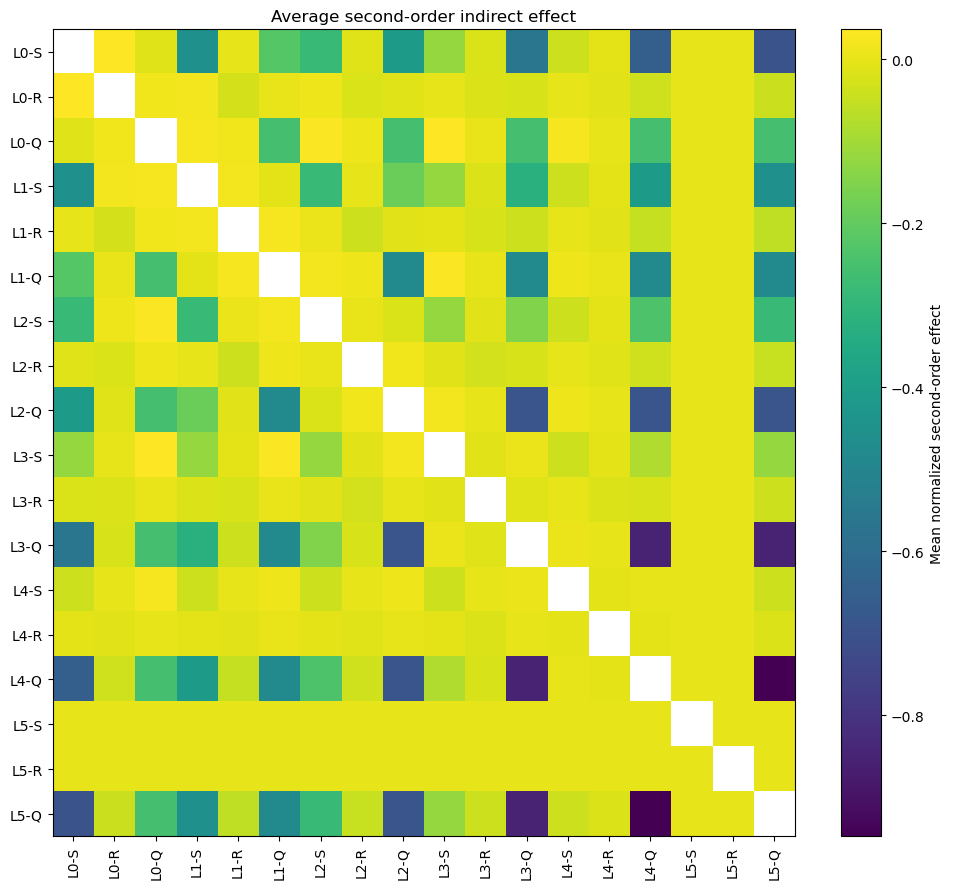

In [37]:
plt.figure(
    figsize=(10, 9)
)

plt.imshow(
    M2,
    aspect="auto"
)

plt.colorbar(
    label="Mean normalized second-order effect"
)

plt.xticks(
    range(len(sites)),
    labels_sites,
    rotation=90
)

plt.yticks(
    range(len(sites)),
    labels_sites
)

plt.title(
    "Average second-order indirect effect"
)

plt.tight_layout()
plt.show()

In [38]:
# Frequenza del segno P(J_D > 0) e P(J_D < 0)
sign_stats = (
    all_pairs
    .groupby(
        ["site_i", "site_j"]
    )
    .agg(
        mean_J=("J_D_norm", "mean"),
        median_J=("J_D_norm", "median"),
        std_J=("J_D_norm", "std"),

        positive_fraction=(
            "J_D_norm",
            lambda x: (x > 0).mean()
        ),

        negative_fraction=(
            "J_D_norm",
            lambda x: (x < 0).mean()
        ),

        n=("J_D_norm", "size")
    )
    .reset_index()
)

In [39]:
print(
    sign_stats
    .sort_values(
        [
            "positive_fraction",
            "mean_J"
        ],
        ascending=False
    )
    .head(20)
)

     site_i  site_j    mean_J  median_J     std_J  positive_fraction  \
42   (0, 3)  (4, 1)  0.023545  0.008449  0.047561            0.75000   
81   (1, 3)  (4, 1)  0.012938  0.013772  0.040969            0.75000   
39   (0, 3)  (3, 1)  0.036468  0.025700  0.072433            0.71875   
36   (0, 3)  (2, 1)  0.031527  0.034682  0.102100            0.65625   
17   (0, 2)  (0, 3)  0.016183  0.010902  0.044915            0.65625   
34   (0, 3)  (1, 2)  0.015910  0.015006  0.051605            0.65625   
87   (2, 1)  (2, 2)  0.003676  0.009351  0.033748            0.65625   
78   (1, 3)  (3, 1)  0.029818  0.017560  0.091726            0.62500   
48   (1, 1)  (1, 2)  0.019772  0.020659  0.057645            0.62500   
0    (0, 1)  (0, 2)  0.033259  0.014827  0.098149            0.59375   
62   (1, 2)  (1, 3)  0.024326  0.014831  0.068929            0.59375   
76   (1, 3)  (2, 2)  0.013238  0.011297  0.050204            0.59375   
111  (2, 3)  (4, 1)  0.011121  0.005750  0.048201            0.5

In [40]:
all_pairs["sign_reversal"] = (
    (all_pairs["IE_i_norm"] <= 0)
    &
    (all_pairs["IE_j_norm"] <= 0)
    &
    (
        all_pairs["IE_i_norm"]
        + all_pairs["IE_j_norm"]
        + all_pairs["J_D_norm"]
        > 0
    )
)

sign_reversal_stats = (
    all_pairs
    .groupby(
        ["site_i", "site_j"]
    )
    ["sign_reversal"]
    .mean()
    .reset_index(
        name="sign_reversal_fraction"
    )
)

print(
    sign_reversal_stats
    .sort_values(
        "sign_reversal_fraction",
        ascending=False
    )
    .head(20)
)

     site_i  site_j  sign_reversal_fraction
22   (0, 2)  (2, 2)                 0.03125
25   (0, 2)  (3, 2)                 0.03125
0    (0, 1)  (0, 2)                 0.00000
105  (2, 2)  (5, 1)                 0.00000
100  (2, 2)  (3, 2)                 0.00000
101  (2, 2)  (3, 3)                 0.00000
102  (2, 2)  (4, 1)                 0.00000
103  (2, 2)  (4, 2)                 0.00000
104  (2, 2)  (4, 3)                 0.00000
106  (2, 2)  (5, 2)                 0.00000
98   (2, 2)  (2, 3)                 0.00000
107  (2, 2)  (5, 3)                 0.00000
108  (2, 3)  (3, 1)                 0.00000
109  (2, 3)  (3, 2)                 0.00000
110  (2, 3)  (3, 3)                 0.00000
111  (2, 3)  (4, 1)                 0.00000
112  (2, 3)  (4, 2)                 0.00000
113  (2, 3)  (4, 3)                 0.00000
99   (2, 2)  (3, 1)                 0.00000
97   (2, 1)  (5, 3)                 0.00000


In [41]:
top_pairs = (
    AIE2
    .sort_values(
        "mean_J",
        ascending=False
    )
    .head(10)
)

boot_rows = []

rng = np.random.default_rng(123)

for _, row in top_pairs.iterrows():

    si = row["site_i"]
    sj = row["site_j"]

    vals = all_pairs[
        (all_pairs["site_i"] == si)
        &
        (all_pairs["site_j"] == sj)
    ]["J_D_norm"].to_numpy()

    boots = []

    for _ in range(2000):

        sample = rng.choice(
            vals,
            size=len(vals),
            replace=True
        )

        boots.append(
            sample.mean()
        )

    boot_rows.append({
        "site_i": si,
        "site_j": sj,

        "mean_J":
            vals.mean(),

        "CI_lo":
            np.percentile(
                boots,
                2.5
            ),

        "CI_hi":
            np.percentile(
                boots,
                97.5
            )
    })

AIE2_boot = pd.DataFrame(
    boot_rows
)

print(AIE2_boot)

   site_i  site_j    mean_J     CI_lo     CI_hi
0  (0, 3)  (3, 1)  0.036468  0.014137  0.063786
1  (0, 1)  (0, 2)  0.033259  0.001961  0.068763
2  (0, 3)  (2, 1)  0.031527 -0.003070  0.064272
3  (1, 3)  (3, 1)  0.029818 -0.000212  0.062166
4  (0, 3)  (1, 1)  0.024667 -0.019271  0.066926
5  (1, 2)  (1, 3)  0.024326  0.001377  0.048013
6  (0, 3)  (4, 1)  0.023545  0.008878  0.040772
7  (1, 3)  (2, 1)  0.020477 -0.022915  0.065636
8  (1, 1)  (1, 2)  0.019772  0.000400  0.039384
9  (2, 3)  (3, 1)  0.018851 -0.012072  0.055993
